# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Fahmi Alfayadh| 5054251015 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pl.read_csv('Live.csv')
df.head()


status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
i64,str,str,i64,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str
1,"""video""","""4/22/2018 6:00""",529,512,262,432,92,3,1,1,0,null,null,null,null
2,"""photo""","""4/21/2018 22:45""",150,0,0,150,0,0,0,0,0,null,null,null,null
3,"""video""","""4/21/2018 6:17""",227,236,57,204,21,1,1,0,0,null,null,null,null
4,"""photo""","""4/21/2018 2:29""",111,0,0,111,0,0,0,0,0,null,null,null,null
5,"""photo""","""4/18/2018 3:22""",213,0,0,204,9,0,0,0,0,null,null,null,null


In [3]:
print(f"shape: {df.shape}")
(df.null_count())

shape: (7050, 16)


status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,7050,7050,7050,7050


column1 sampai column4 null semua (7050/7050), di drop.

In [4]:
df = df.drop(["Column1", "Column2", "Column3", "Column4"])
df = df.drop("status_id")

In [5]:
(df.null_count())

status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0


In [6]:
import polars.selectors as cs

numeric_cols = df.select(cs.numeric()).columns
cat_cols = df.select(~cs.numeric()).columns

In [7]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
# Hitung metrik langsung ke tabel

(df.select(cs.numeric().skew()))

num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
f64,f64,f64,f64,f64,f64,f64,f64,f64
3.737657,9.026929,7.097822,3.918294,6.003567,18.24293,20.301421,17.575127,19.502978


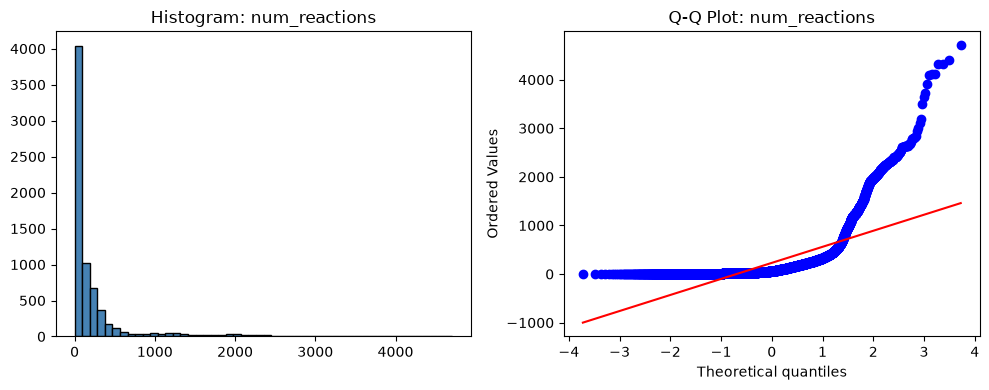

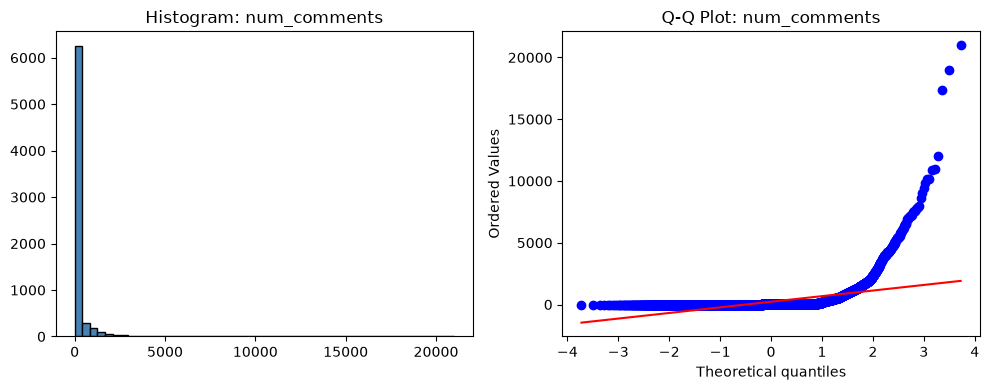

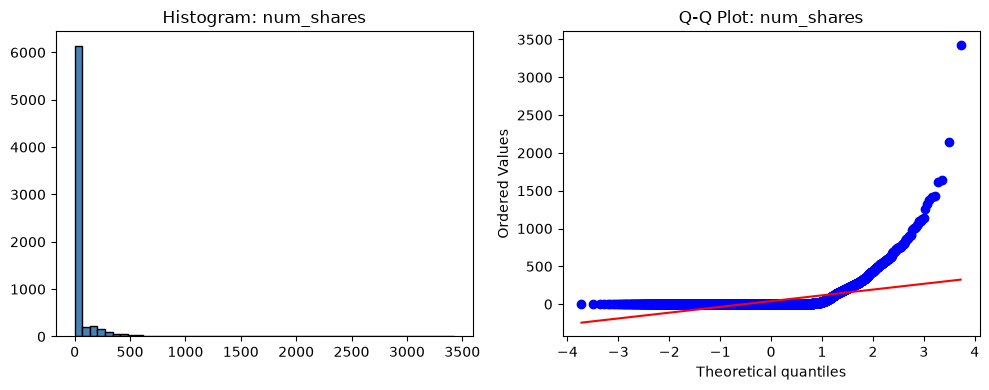

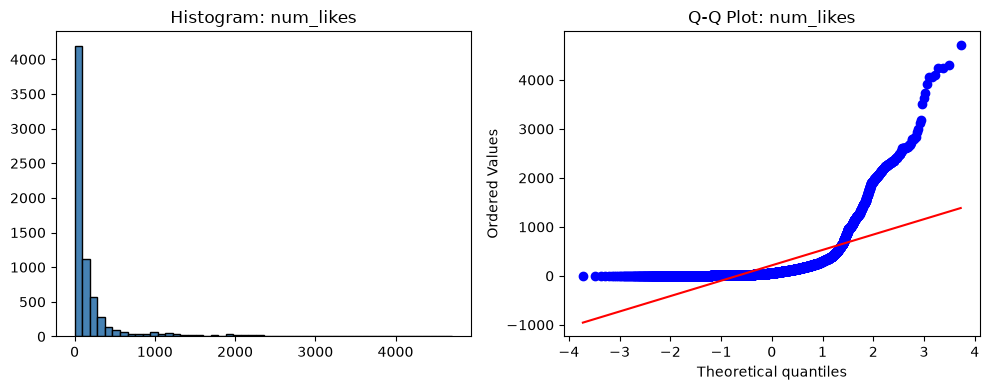

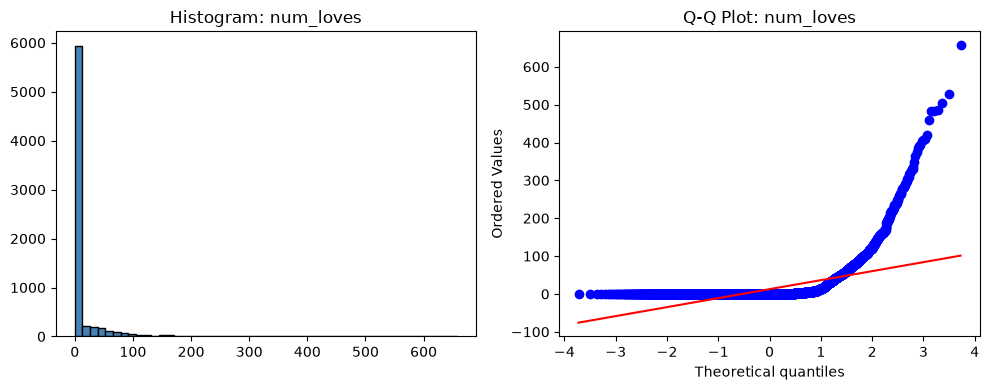

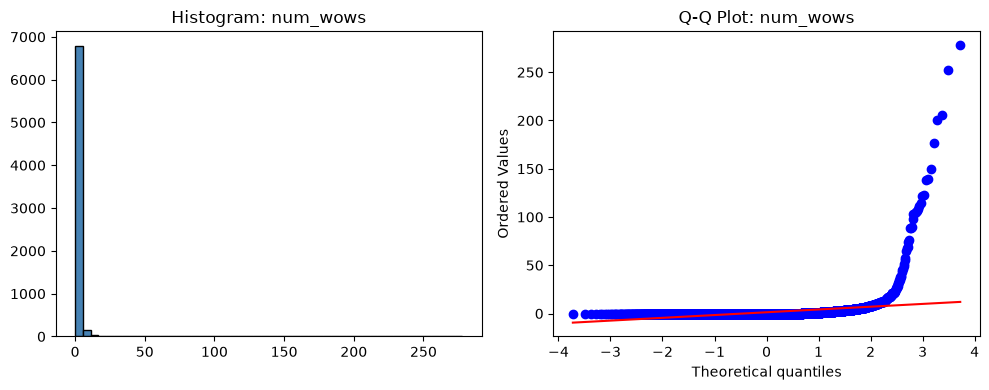

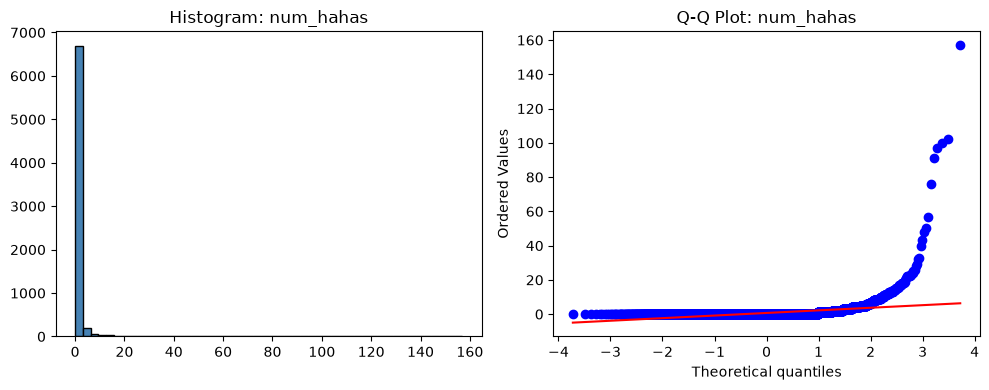

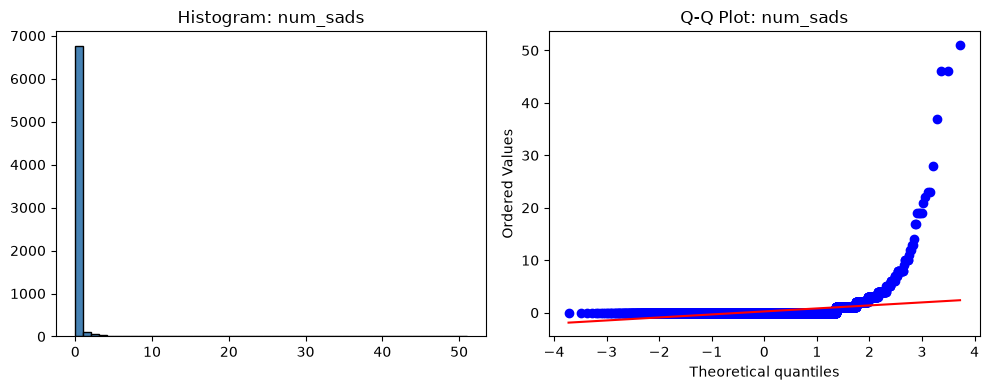

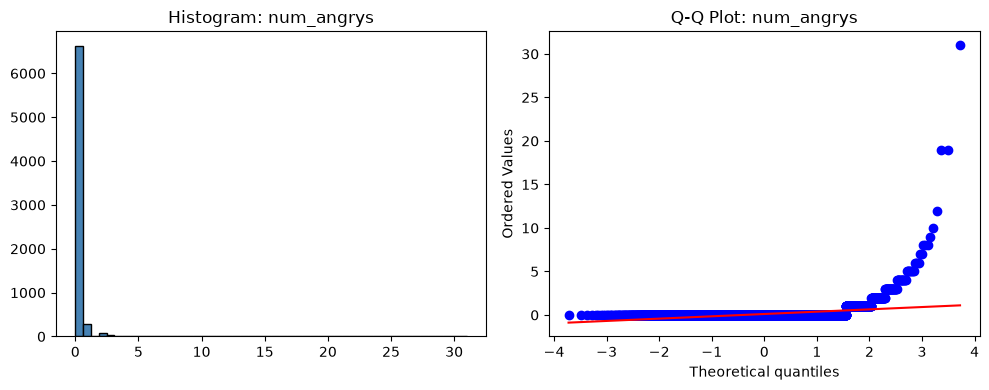

In [8]:
import matplotlib.pyplot as plt
import scipy.stats as stats


for kolom in numeric_cols:
    arr = df[kolom].to_numpy()

    plt.figure(figsize=(10, 4))

    # Histogram
    plt.subplot(1, 2, 1)
    plt.hist(arr, bins=50, edgecolor="black", color="steelblue")
    plt.title(f"Histogram: {kolom}")

    # Q-Q Plot terhadap distribusi normal teoritis
    plt.subplot(1, 2, 2)
    stats.probplot(arr, dist="norm", plot=plt)
    plt.title(f"Q-Q Plot: {kolom}")

    plt.tight_layout()
    plt.show()


Semua data skew ke kanan, sehingga perlu dilakukan transformasi log untuk mengurangi skewness.

<Axes: >

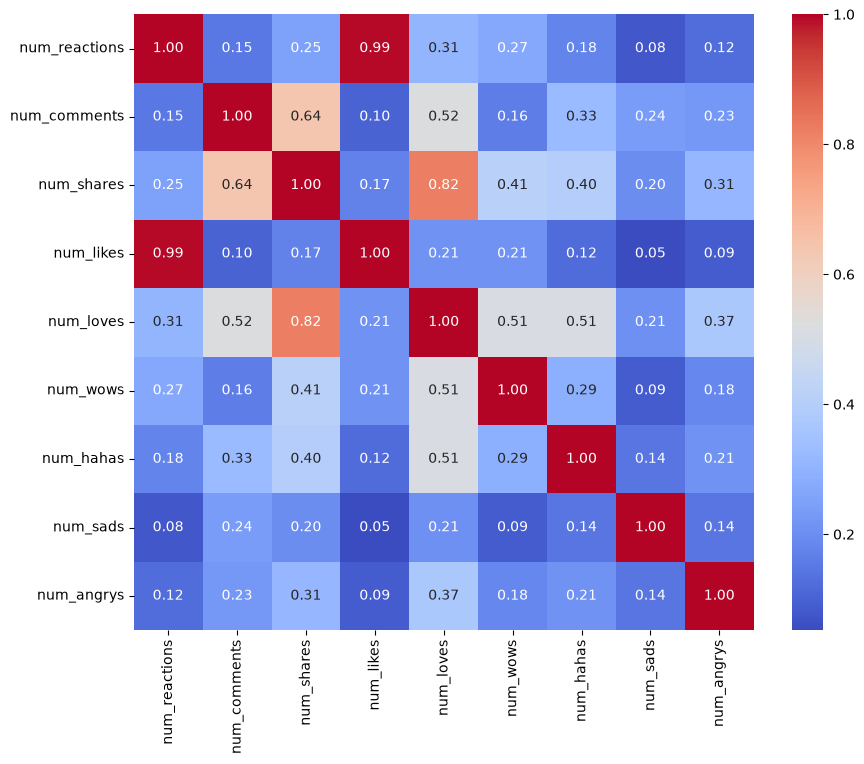

In [9]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(df.select(cs.numeric()).to_pandas().corr(), annot=True, cmap="coolwarm", fmt=".2f")

In [ ]:
## fitur dgn korelasi tinggi (> 0.9) (drop salah satunya)
df.select(cs.numeric()).to_pandas().corr().unstack().sort_values(ascending=False).drop_duplicates().loc[lambda x: (x > 0.85) & (x < 1)]

num_likes  num_reactions    0.994923
dtype: float64

In [ ]:
df = df.drop("num_reactions")

In [43]:
df.with_columns(pl.col("status_published"))

status_type,status_published,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
str,str,i64,i64,i64,i64,i64,i64,i64,i64
"""video""","""4/22/2018 6:00""",512,262,432,92,3,1,1,0
"""photo""","""4/21/2018 22:45""",0,0,150,0,0,0,0,0
"""video""","""4/21/2018 6:17""",236,57,204,21,1,1,0,0
"""photo""","""4/21/2018 2:29""",0,0,111,0,0,0,0,0
"""photo""","""4/18/2018 3:22""",0,0,204,9,0,0,0,0
…,…,…,…,…,…,…,…,…,…
"""photo""","""9/24/2016 2:58""",0,0,89,0,0,0,0,0
"""photo""","""9/23/2016 11:19""",0,0,14,1,0,1,0,0
"""photo""","""9/21/2016 23:03""",0,0,1,1,0,0,0,0


/tmp/ipykernel_155340/1888232409.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df.to_pandas(), x="year", palette="viridis")


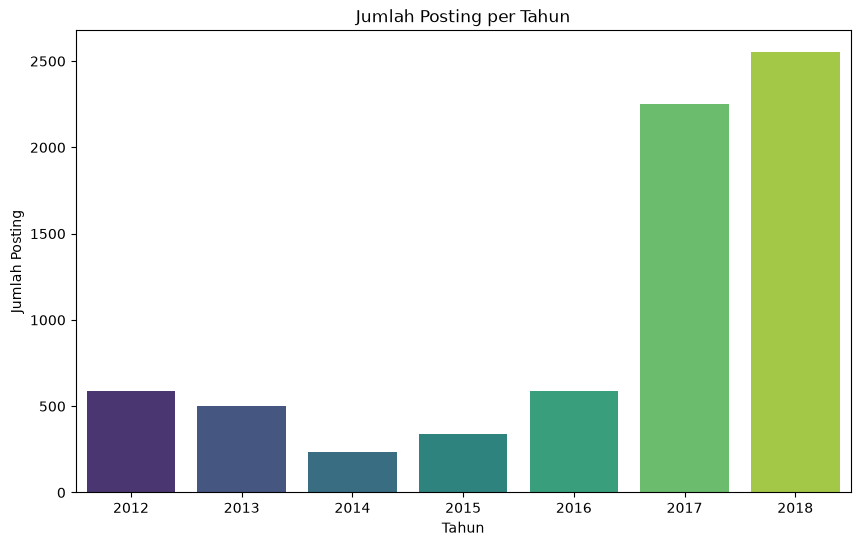

In [46]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
# PERBAIKAN: Menggunakan garis miring (/) sesuai dengan data asli Anda
df = df.with_columns(
    pl.col("status_published")
    .str.strptime(pl.Datetime, format="%m/%d/%Y %H:%M")
    .alias("status_published")
)

df = df.with_columns(pl.col("status_published").dt.year().alias("year"))

plt.figure(figsize=(10, 6))
sns.countplot(data=df.to_pandas(), x="year", palette="viridis")
plt.title("Jumlah Posting per Tahun")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Posting")
plt.show()

/tmp/ipykernel_155340/4066192541.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df.to_pandas(), x="status_type", y="num_likes", palette="viridis")


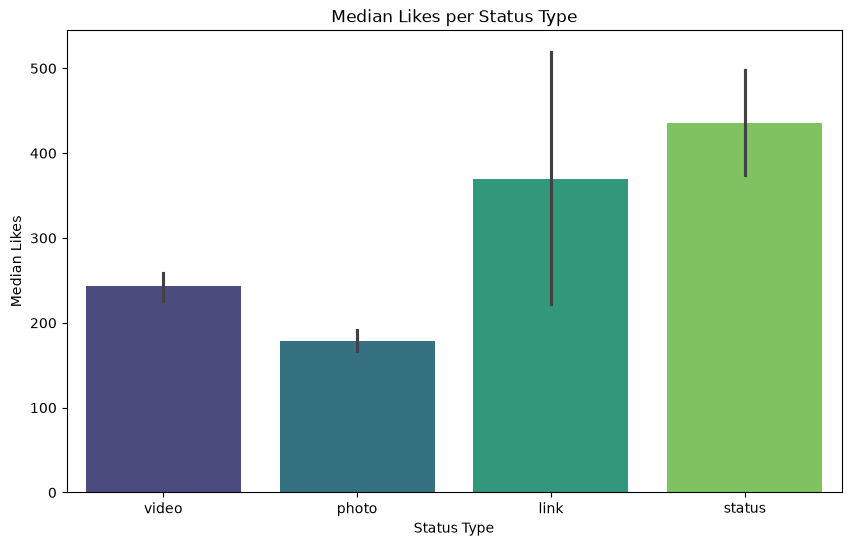

In [49]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
df.group_by("status_type").agg(
    pl.col("num_likes").median().alias("median_likes"),
    pl.col("num_comments").median().alias("median_comments"),
    pl.col("num_shares").median().alias("median_shares")
)
plt.figure(figsize=(10, 6))
sns.barplot(data=df.to_pandas(), x="status_type", y="num_likes", palette="viridis")
plt.title("Median Likes per Status Type")
plt.xlabel("Status Type")
plt.ylabel("Median Likes")
plt.show()

status dan like memiliki median likes yg tinggi dibandiingkan video dan photo

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [53]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
df.null_count()

status_type,status_published,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,year
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0


In [55]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.

df_clustering = df.select(cs.numeric())

In [56]:
numeric_cols

['num_reactions',
 'num_comments',
 'num_shares',
 'num_likes',
 'num_loves',
 'num_wows',
 'num_hahas',
 'num_sads',
 'num_angrys']

**Fitur yang dipilih untuk clustering:** (`num_likes`, `num_comments`, `num_shares`, `num_wows`, `num_hahas`, `num_sads`, `num_angrys`)

yang saya drop adalah num_reactions karena dari hasil korelasi, num_reactions memiliki korelasi tinggi dengan num_likes, sehingga bisa di drop salah satunya.

`num_sad`, `num_hahas`, dan `num_wow` saya keep karena masing-masing memiliki makna yang berbeda dan berguna sebagai fitur clustering.

In [57]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

log_transformer = FunctionTransformer(np.log1p, validate=True)
log_transformer.fit(df_clustering.to_numpy())
df_clustering_log = log_transformer.transform(df_clustering.to_numpy())

In [60]:
df_clustering_log = pl.DataFrame(df_clustering_log, schema=df_clustering.columns)
df_clustering_log

num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,year
f64,f64,f64,f64,f64,f64,f64,f64,f64
6.240276,5.572154,6.070738,4.532599,1.386294,0.693147,0.693147,0.0,7.610358
0.0,0.0,5.01728,0.0,0.0,0.0,0.0,0.0,7.610358
5.46806,4.060443,5.32301,3.091042,0.693147,0.693147,0.0,0.0,7.610358
0.0,0.0,4.718499,0.0,0.0,0.0,0.0,0.0,7.610358
0.0,0.0,5.32301,2.302585,0.0,0.0,0.0,0.0,7.610358
…,…,…,…,…,…,…,…,…
0.0,0.0,4.49981,0.0,0.0,0.0,0.0,0.0,7.609367
0.0,0.0,2.70805,0.693147,0.0,0.693147,0.0,0.0,7.609367
0.0,0.0,0.693147,0.693147,0.0,0.0,0.0,0.0,7.609367


Distribusi fitur setelah transformasi log1p:


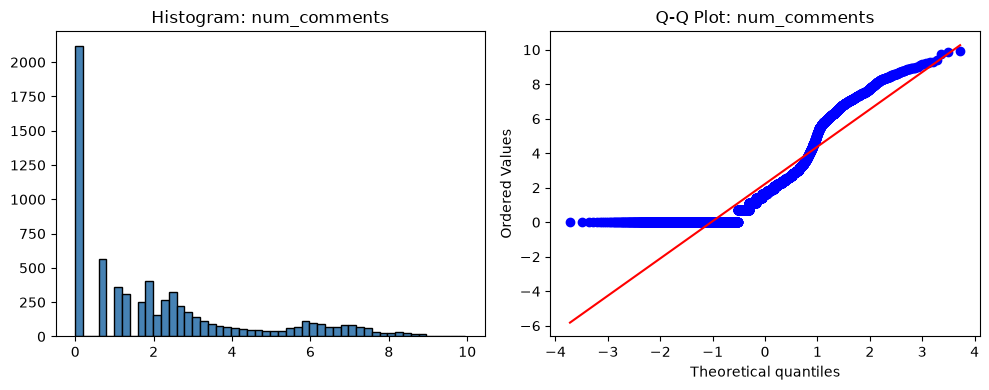

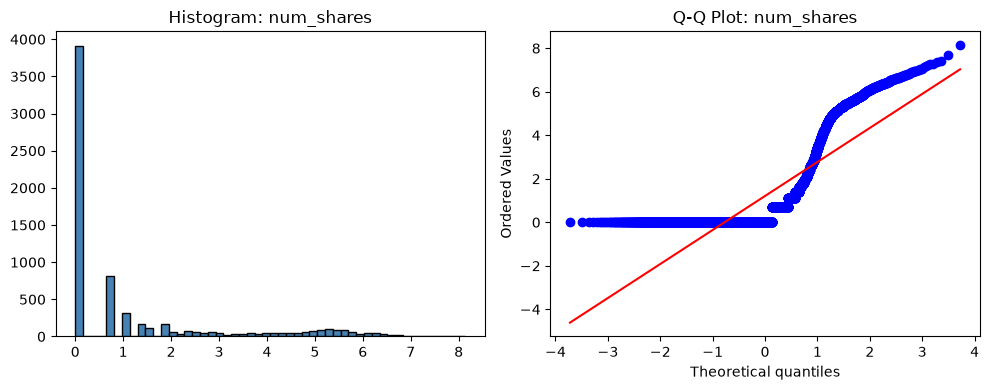

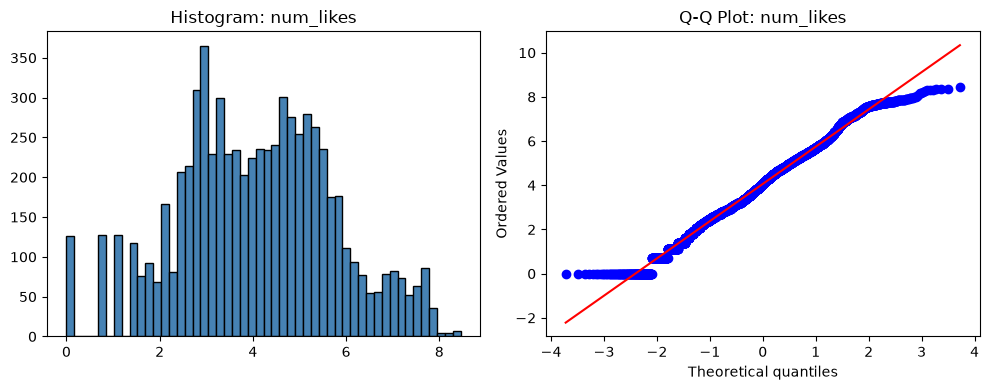

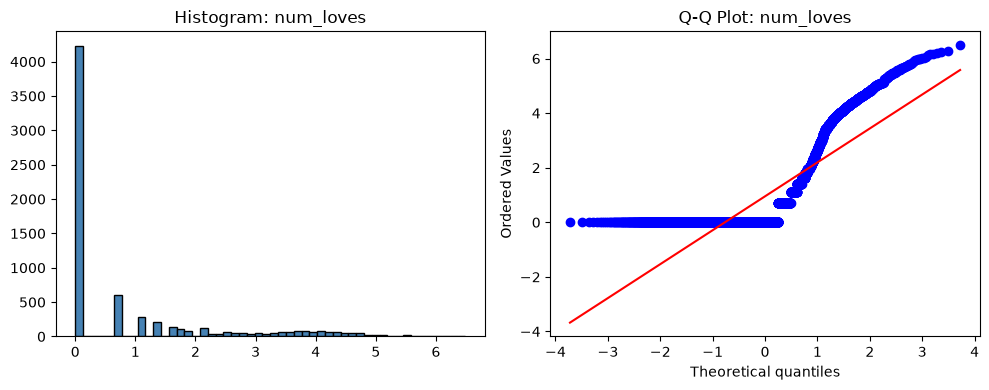

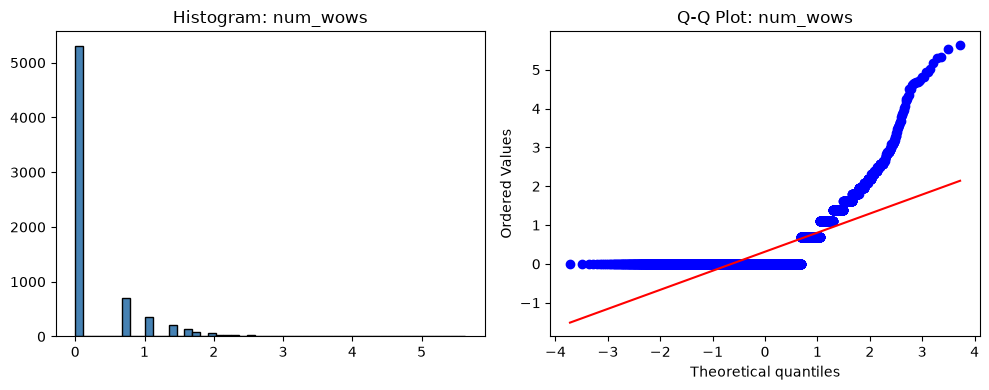

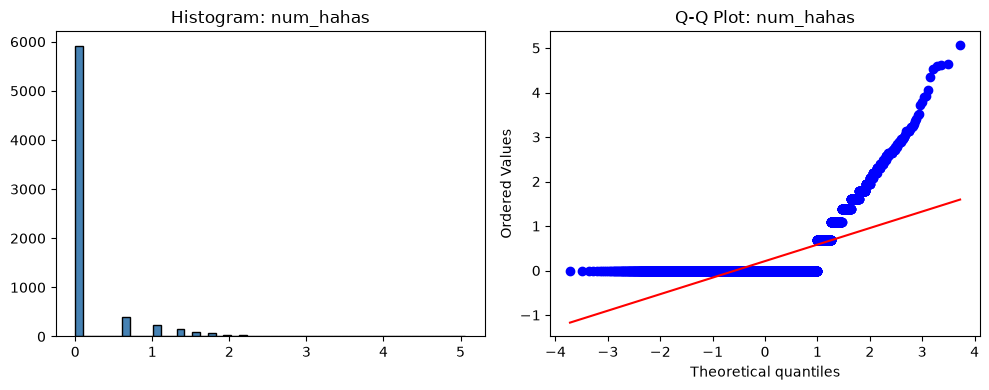

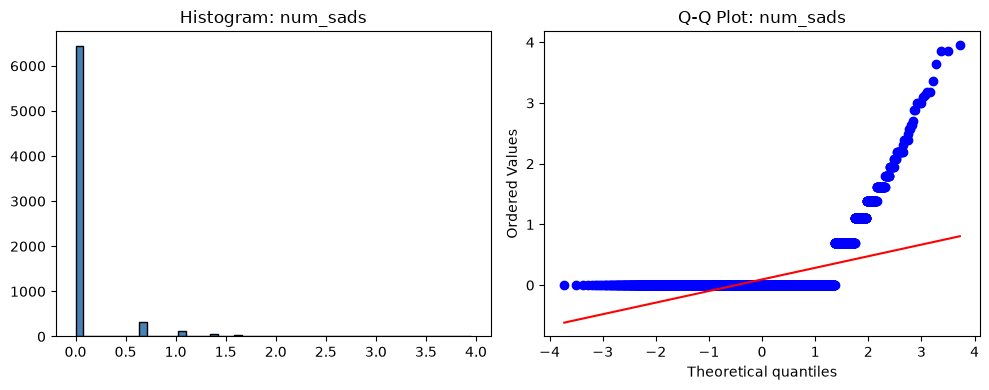

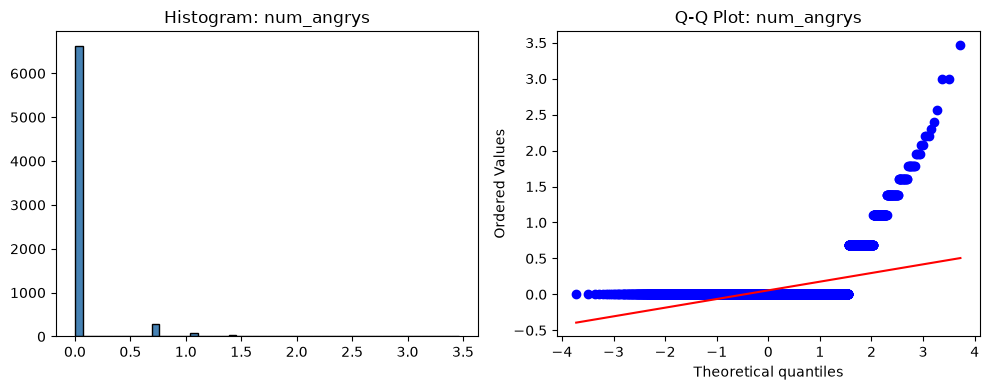

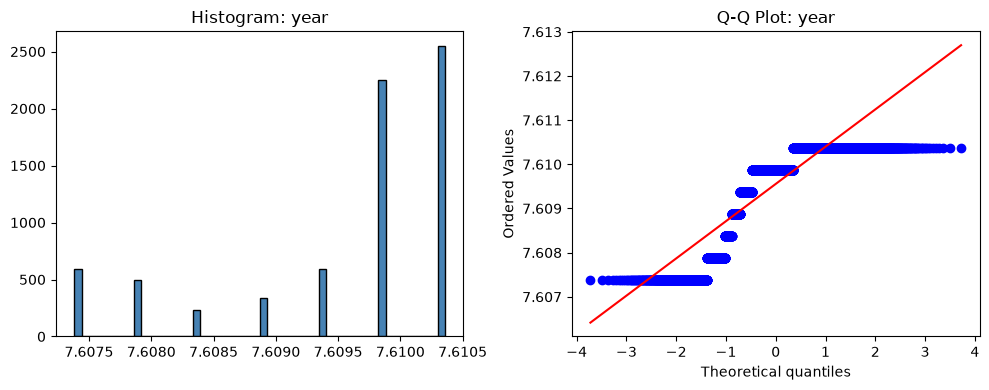

In [62]:
### setleah di skew
import matplotlib.pyplot as plt
import scipy.stats as stats
print("Distribusi fitur setelah transformasi log1p:")
for kolom in df_clustering_log.columns:
    arr = df_clustering_log[kolom].to_numpy()

    plt.figure(figsize=(10, 4))

    # Histogram
    plt.subplot(1, 2, 1)
    plt.hist(arr, bins=50, edgecolor="black", color="steelblue")
    plt.title(f"Histogram: {kolom}")

    # Q-Q Plot terhadap distribusi normal teoritis
    plt.subplot(1, 2, 2)
    stats.probplot(arr, dist="norm", plot=plt)
    plt.title(f"Q-Q Plot: {kolom}")

    plt.tight_layout()
    plt.show()


In [66]:
#skew
df_clustering_log.select(cs.numeric().skew())

num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,year
f64,f64,f64,f64,f64,f64,f64,f64,f64
1.037282,1.525696,-0.014452,1.503464,2.810007,3.11356,4.714327,5.297222,-1.193016


In [68]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
from sklearn.preprocessing import StandardScaler


X_raw = df_clustering.to_numpy()
X_raw_scaled = StandardScaler().fit_transform(X_raw)
X_log_scaled = StandardScaler().fit_transform(df_clustering_log.to_numpy())

# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [72]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
from sklearn.base import clone

from sklearn.cluster import KMeans


pipeline_kmeans = Pipeline([
    ('kmeans', KMeans(n_clusters=3, random_state=42, n_init=10))
])

kmeans_raw = clone(pipeline_kmeans).fit(X_raw)
kmeans_raw_scaled = clone(pipeline_kmeans).fit(X_raw_scaled)
kmeans_log_scaled = clone(pipeline_kmeans).fit(X_log_scaled)

            Dataset       Inertia  Silhouette Score
0  Raw (No Scaling)  2.387831e+09          0.788565
1      Raw + Scaled  4.203093e+04          0.502006
2      Log + Scaled  3.276006e+04          0.329195


/tmp/ipykernel_155340/1782850518.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_eval, x="Dataset", y="Silhouette Score", palette="Set2")


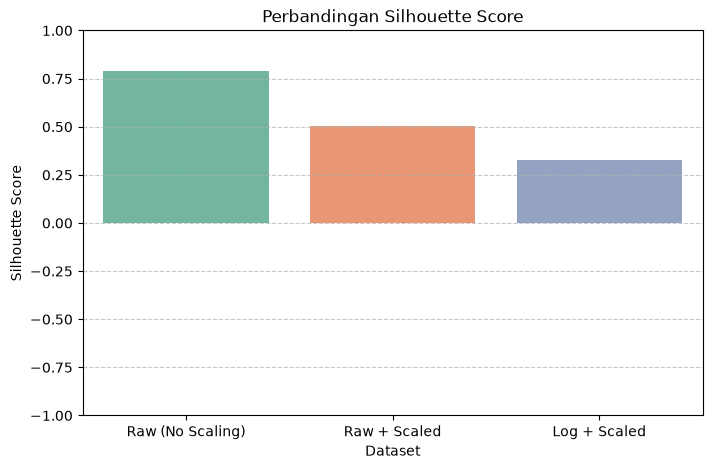

In [74]:
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
from sklearn.metrics import silhouette_score
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Buat list untuk menampung hasil metrik evaluasi
eval_results = []

# Definisikan data dan model yang berpasangan
datasets = {
    "Raw (No Scaling)": (X_raw, kmeans_raw),
    "Raw + Scaled": (X_raw_scaled, kmeans_raw_scaled),
    "Log + Scaled": (X_log_scaled, kmeans_log_scaled)
}

for name, (X_data, model) in datasets.items():
    # Ambil label klaster dari langkah 'kmeans' di dalam pipeline
    labels = model.named_steps['kmeans'].labels_
    inertia = model.named_steps['kmeans'].inertia_
    
    # Hitung silhouette score
    sil_score = silhouette_score(X_data, labels)
    
    eval_results.append({
        "Dataset": name,
        "Inertia": inertia,
        "Silhouette Score": sil_score
    })

# Konversi hasil evaluasi ke DataFrame untuk plotting
df_eval = pd.DataFrame(eval_results)
print(df_eval)

# Visualisasi perbandingan Silhouette Score
plt.figure(figsize=(8, 5))
sns.barplot(data=df_eval, x="Dataset", y="Silhouette Score", palette="Set2")
plt.title("Perbandingan Silhouette Score")
plt.ylabel("Silhouette Score")
plt.ylim(-1, 1) # Range score silhouette adalah -1 sampai 1
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


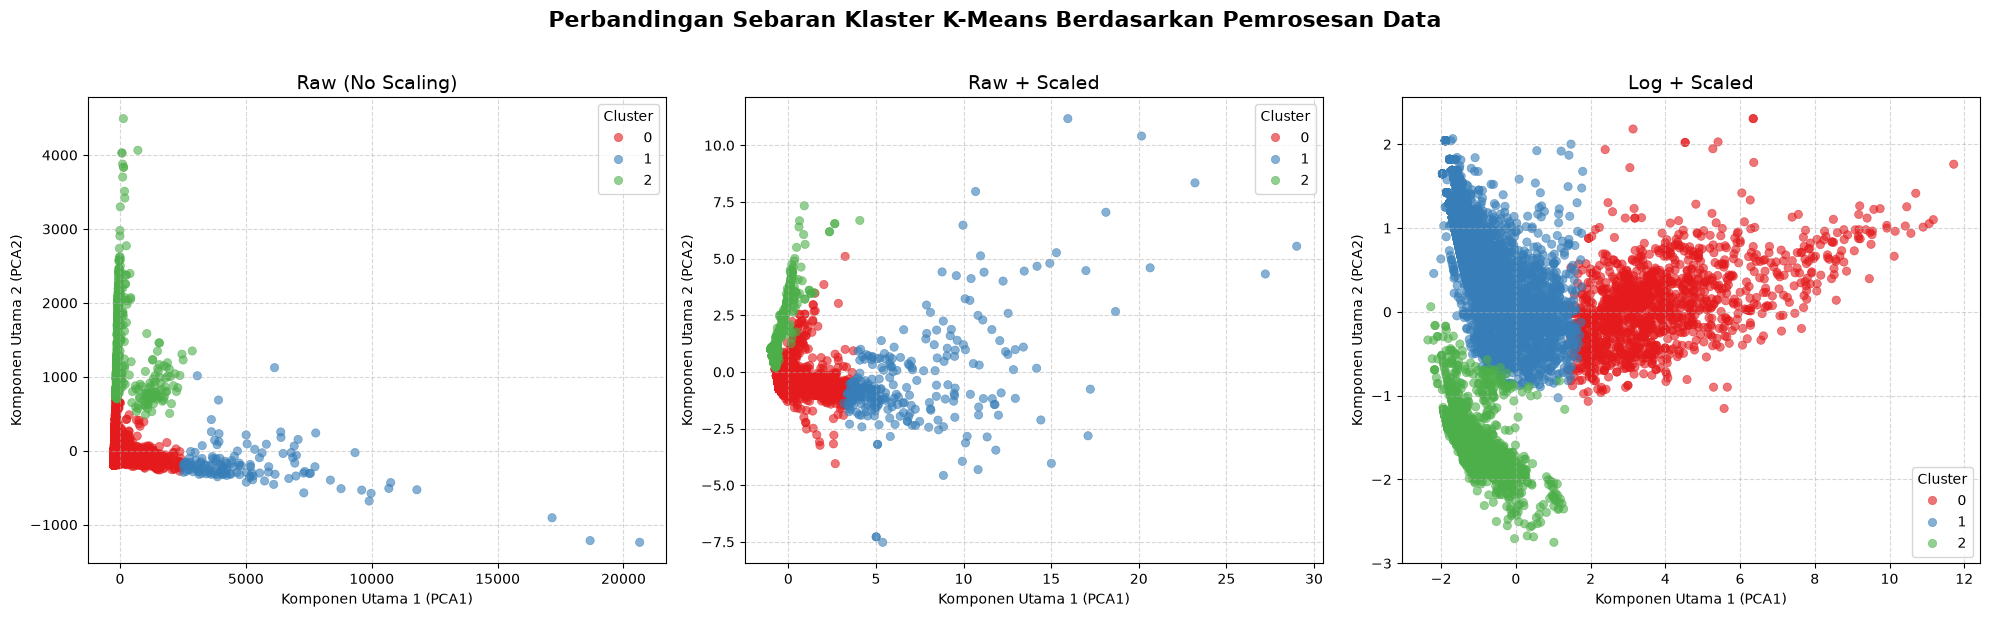

In [75]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Siapkan subplots berdampingan (1 baris, 3 kolom)
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=False)

datasets_vis = [
    ("Raw (No Scaling)", X_raw, kmeans_raw),
    ("Raw + Scaled", X_raw_scaled, kmeans_raw_scaled),
    ("Log + Scaled", X_log_scaled, kmeans_log_scaled)
]

for idx, (title, X_data, model) in enumerate(datasets_vis):
    # Dapatkan label klaster dari pipeline
    labels = model.named_steps['kmeans'].labels_
    
    # Reduksi menjadi 2 komponen utama menggunakan PCA
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_data)
    
    # Masukkan ke DataFrame untuk memudahkan plotting dengan Seaborn
    df_plot = pd.DataFrame(X_pca, columns=["PCA1", "PCA2"])
    df_plot["Cluster"] = labels.astype(str) # Ubah ke string agar warna diskrit
    
    # Urutkan berdasarkan nama klaster agar warna konsisten
    df_plot = df_plot.sort_values("Cluster")
    
    # Gambar scatter plot pada axis yang sesuai
    sns.scatterplot(
        data=df_plot, 
        x="PCA1", 
        y="PCA2", 
        hue="Cluster", 
        ax=axes[idx], 
        palette="Set1", 
        alpha=0.6,
        edgecolor=None
    )
    
    axes[idx].set_title(title, fontsize=14)
    axes[idx].set_xlabel("Komponen Utama 1 (PCA1)")
    axes[idx].set_ylabel("Komponen Utama 2 (PCA2)")
    axes[idx].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Perbandingan Sebaran Klaster K-Means Berdasarkan Pemrosesan Data", fontsize=16, weight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [18]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.

In [19]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [20]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.

In [21]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.

**Pilihan k untuk K-Means:** (isi nilai k yang kalian pilih beserta alasan singkatnya)

## 3.4 Model K-Means Final

In [22]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.

In [23]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.

# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

In [24]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.

In [25]:
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [26]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.

In [27]:
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).

**Pilihan linkage untuk Hierarchical Clustering:** (isi linkage yang kalian pilih beserta alasan singkatnya)

## 4.3 Model Hierarchical Clustering Final

In [28]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.

In [29]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.

# 5. Evaluasi Model

In [30]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.

In [31]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.

In [32]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.

# 6. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Jelaskan pengaruh transformasi log dan feature scaling pada K-Means berdasarkan hasil pada bagian 3.1. Mengapa keduanya penting pada algoritma berbasis jarak, terutama untuk data yang sangat miring dan mengandung outlier ekstrem?
- Bagaimana kalian menangani kolom yang redundan atau banyak bernilai nol (misalnya reaksi emoji)? Jelaskan alasan pemilihan fitur kalian.
- Berapa jumlah cluster optimal menurut Elbow Method dan Silhouette Score? Apakah keduanya menghasilkan kesimpulan yang sama? Jika berbeda, mana yang kalian pilih dan mengapa?
- Bandingkan hasil keempat metode linkage pada Hierarchical Clustering. Linkage mana yang paling baik dan mengapa? Bagaimana karakteristik cluster yang dihasilkan oleh single linkage?
- Bandingkan performa K-Means vs Hierarchical Clustering berdasarkan metrik internal dan visualisasi PCA. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Bagaimana karakteristik tiap cluster berdasarkan profil median fitur dan komposisi status_type? Beri nama atau julukan yang menggambarkan tiap cluster.
- Apa kelebihan dan kekurangan masing-masing metode (misalnya dari sisi kebutuhan menentukan k di awal, bentuk cluster, dan kebutuhan waktu serta memori)?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

# 7. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya melakukan clustering terpisah untuk periode sebelum dan sesudah tahun 2016, memanfaatkan fitur waktu seperti jam atau hari posting, mencoba algoritma clustering lain seperti DBSCAN atau Gaussian Mixture Model, melakukan reduksi dimensi sebelum clustering, atau mencoba variasi hyperparameter lain seperti n_init dan init pada K-Means), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.